Task 1: Load the dataset into a Pandas DataFrame

Explanation: Loads the .csv into a pandas dataframe.


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

df = pd.read_csv('heart_disease_uci.csv')


Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

Explanation: Uses head(), info(), and describe() to view the dataframe
    

In [6]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


Task 3: Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.
          
Explanation: Converts "?" to null across the df, along with 0 in chol and trestbps as they are not valid placeholders.I then split the df into categorical and numeric, using most_frequent and median strategies repectively. I finally place these imputed columns into an a seperate imputed df.

In [17]:
df = df.replace("?", np.nan)
df.loc[df["chol"] == 0, "chol"] = np.nan
df.loc[df["trestbps"] == 0, "trestbps"] = np.nan

median_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
mode_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

median_imputer = SimpleImputer(strategy="median")
mode_imputer = SimpleImputer(strategy="most_frequent")

df_imputed = df.copy()
df_imputed[median_cols] = median_imputer.fit_transform(df[median_cols])
df_imputed[mode_cols] = mode_imputer.fit_transform(df[mode_cols])

Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

Explanation: Prepares and the inputs and target, splits the data 80/20,
and isolates the numeric and categorical groups based on the median and most_frequent split. Then builds the column transformerusing StandardScalar for numeric columns and OneHotEncoder for the categorical columns. I wrap it in a pipeline so that the scaling and encoding are fitted on the training set and the applied to the test set. Finally I fit the preprocessor on the training set.


In [19]:
df_imputed["target"] = (df_imputed["num"] > 0).astype(int)
X = df_imputed.drop(columns=["id", "dataset", "num", "target"])
y = df_imputed["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}\n")

numeric_features = median_cols
categorical_features = mode_cols

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

preprocess_pipe = Pipeline([("preprocessor", preprocessor)])

X_train_transformed = preprocess_pipe.fit_transform(X_train)
X_test_transformed = preprocess_pipe.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]


Training set shape: (736, 13)
Testing set shape: (184, 13)
Class distribution in y_train:
target
1    0.552989
0    0.447011
Name: proportion, dtype: float64



Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

Explanation: Builds on the pipeline using the preprocessor from task 4 and the SVC, training it on the training set. It then is evaluated on the test set using the confusion matrix, classification report, and ROC-AUC. This is set in a function so that the identical metrics are used in tasks 6 and 7.

===== SVC (RBF kernel) =====
Confusion matrix (rows = true, columns = predicted):
                  Pred: No disease  Pred: Disease
True: No disease                60             22
True: Disease                   10             92

Classification report:
              precision    recall  f1-score   support

  No disease       0.86      0.73      0.79        82
     Disease       0.81      0.90      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.82      0.82       184
weighted avg       0.83      0.83      0.82       184

ROC-AUC: 0.8984



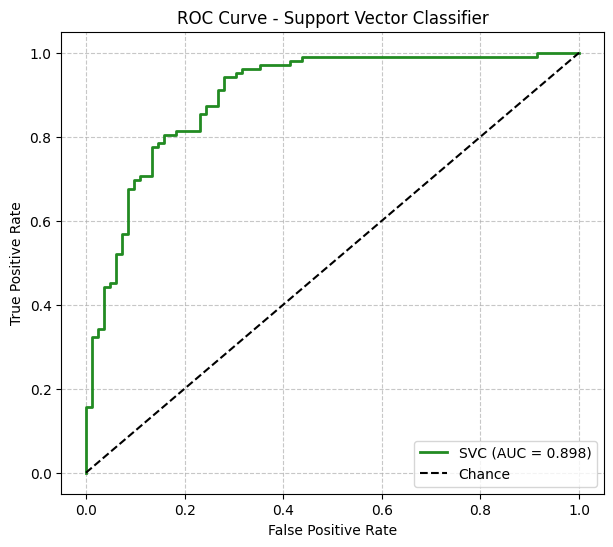

In [20]:
def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"===== {name} =====")
    print("Confusion matrix (rows = true, columns = predicted):")
    print(pd.DataFrame(confusion_matrix(y_test, y_pred),
                       index=["True: No disease", "True: Disease"],
                       columns=["Pred: No disease", "Pred: Disease"]))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))
    auc = roc_auc_score(y_test, y_prob)
    print(f"ROC-AUC: {auc:.4f}\n")
    return roc_curve(y_test, y_prob), auc

svc_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("svc", SVC(C=1.0, kernel="rbf", probability=True, random_state=42)),
])
svc_clf.fit(X_train, y_train)

(svc_fpr, svc_tpr, _), svc_auc = evaluate_model("SVC (RBF kernel)", svc_clf)

plt.figure(figsize=(7, 6))
plt.plot(svc_fpr, svc_tpr, color="forestgreen", linewidth=2, label=f"SVC (AUC = {svc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Support Vector Classifier")
plt.legend(loc="lower right")
plt.grid(linestyle="--", alpha=0.7)
plt.show()

Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

Explanation: Builds a pipeline with the same preprocessor followed by DecisionTreeClassifier. Trains it on the training set and evaluates it with evaluates it using the function we created in task 5. Plots the Decision Tree's ROC curve on the same axes as the SVC's so the two models can be compared directly. Finally Prints a side-by-side table of training accuracy, test accuracy and ROC-AUC for both models.

===== Decision Tree (max_depth=4, min_samples_leaf=5) =====
Confusion matrix (rows = true, columns = predicted):
                  Pred: No disease  Pred: Disease
True: No disease                62             20
True: Disease                   24             78

Classification report:
              precision    recall  f1-score   support

  No disease       0.72      0.76      0.74        82
     Disease       0.80      0.76      0.78       102

    accuracy                           0.76       184
   macro avg       0.76      0.76      0.76       184
weighted avg       0.76      0.76      0.76       184

ROC-AUC: 0.8560



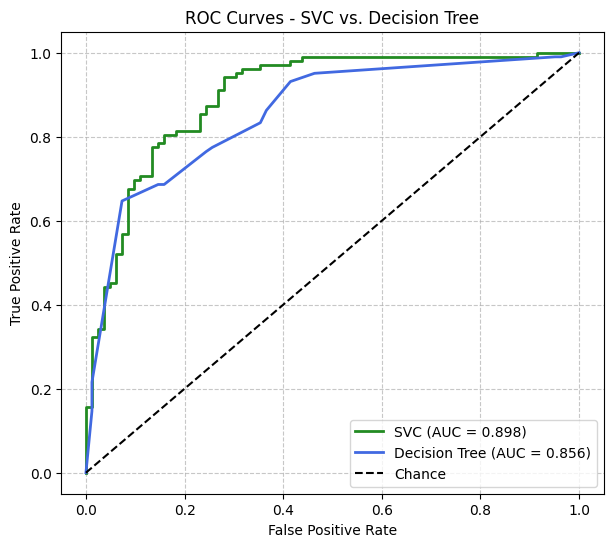

Model comparison:
               Train accuracy  Test accuracy  ROC-AUC
SVC (RBF)               0.868          0.826    0.898
Decision Tree           0.810          0.761    0.856


In [21]:
dt_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)),
])
dt_clf.fit(X_train, y_train)

(dt_fpr, dt_tpr, _), dt_auc = evaluate_model("Decision Tree (max_depth=4, min_samples_leaf=5)", dt_clf)

plt.figure(figsize=(7, 6))
plt.plot(svc_fpr, svc_tpr, color="forestgreen", linewidth=2, label=f"SVC (AUC = {svc_auc:.3f})")
plt.plot(dt_fpr, dt_tpr, color="royalblue", linewidth=2, label=f"Decision Tree (AUC = {dt_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - SVC vs. Decision Tree")
plt.legend(loc="lower right")
plt.grid(linestyle="--", alpha=0.7)
plt.show()

comparison = pd.DataFrame({
    "Train accuracy": [svc_clf.score(X_train, y_train), dt_clf.score(X_train, y_train)],
    "Test accuracy":  [svc_clf.score(X_test, y_test),  dt_clf.score(X_test, y_test)],
    "ROC-AUC":        [svc_auc, dt_auc],
}, index=["SVC (RBF)", "Decision Tree"]).round(3)
print("Model comparison:")
print(comparison)

Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

Explanation: Defines a parameter grid and runs GridSearchCV on the SVC pipeline with 5-fold cross validation.

In [25]:
Cs = [0.1, 1, 10, 100]
gammas = ["scale", 0.001, 0.01, 0.1, 1]
param_grid = {"svc__C": Cs, "svc__gamma": gammas}

grid = GridSearchCV(svc_clf, param_grid, cv=5)
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['age',
                                                                          'trestbps',
                                                                          'chol',
                                                                          'thalch',
                                                                          'oldpeak']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sparse_output=False),
                                                                         ['sex',
                                                                          'cp',
                                                                          'fbs',
                                                                          'restecg',
                                                                          'exang',
                                                                          'slope',
                                                                          'ca',
                                                                          'thal'])])),
                                       ('svc',
                                        SVC(probability=True,
                                            random_state=42))]),
             param_grid={'svc__C': [0.1, 1, 10, 100],
                         'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]})

Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

Explanation: Extracts the trained DecisionTreeClassifier from the pipeline and the names of the transformed features (one-hot columns such as cp_asymptomatic included), and draws the tree.

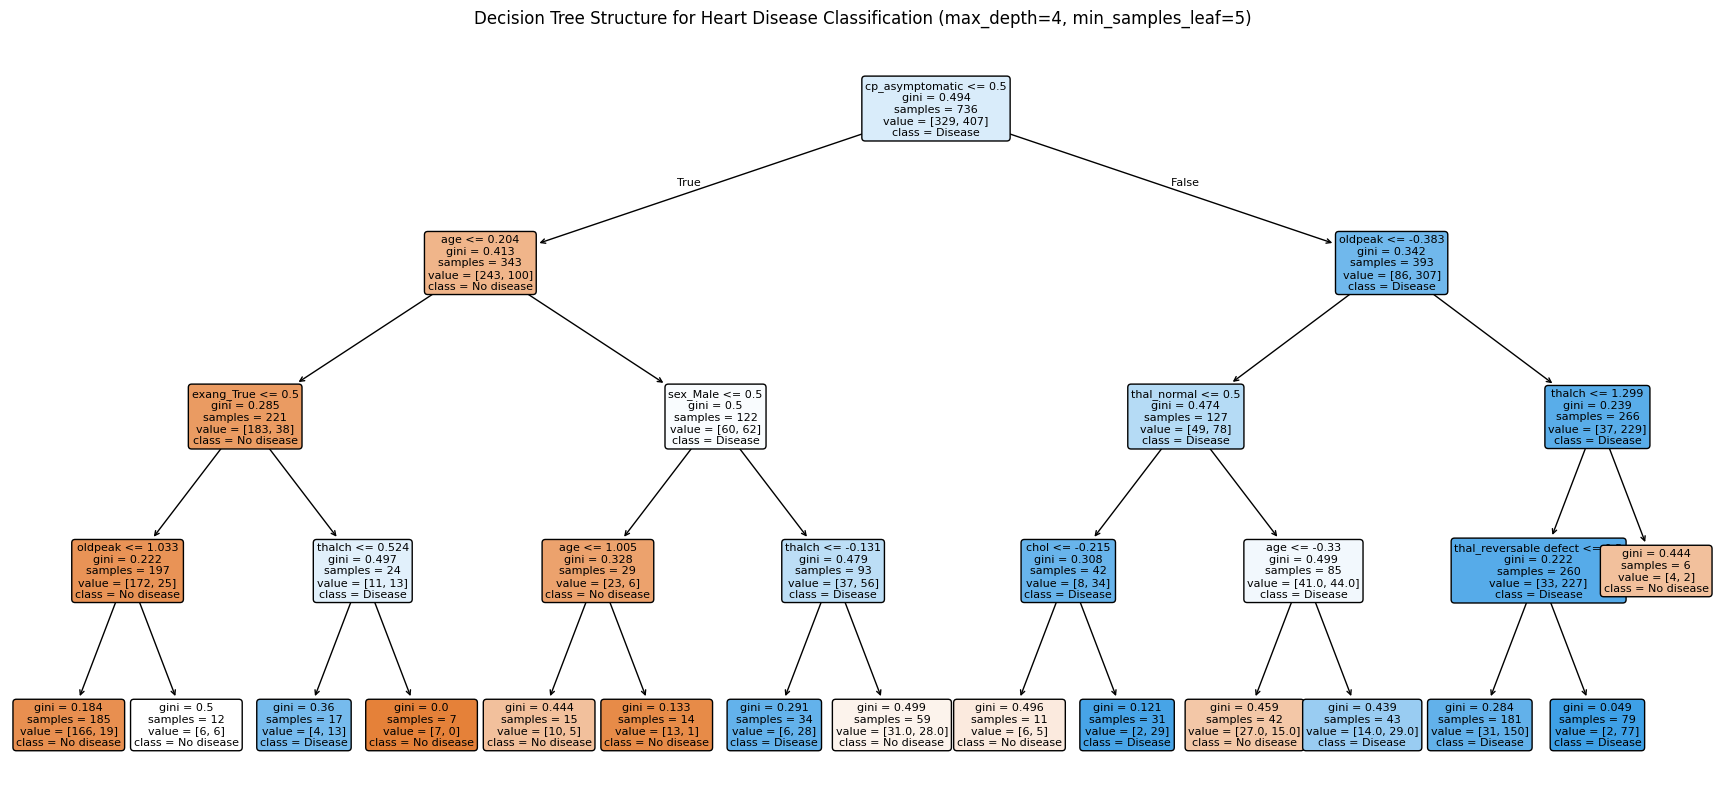

In [26]:
tree_model = dt_clf.named_steps["tree"]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree Structure for Heart Disease Classification (max_depth=4, min_samples_leaf=5)")
plt.show()